<a href="https://colab.research.google.com/github/sanchit-Thakur/ML-COURSE/blob/main/KNN_%26_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data Standardized successfully.

--- PCA Summary ---
Original shape: (150, 4)
Reduced shape: (150, 2)
Explained Variance Ratio: [0.72962445 0.22850762]

--- K-Means Clustering ---
K-Means Cluster Centers:
 [[ 0.57262144 -0.80720888]
 [-2.22475316  0.28892745]
 [ 1.72103664  0.60288719]]
K-Means Labels assigned successfully.

--- Hierarchical Clustering ---
Hierarchical Labels assigned successfully.



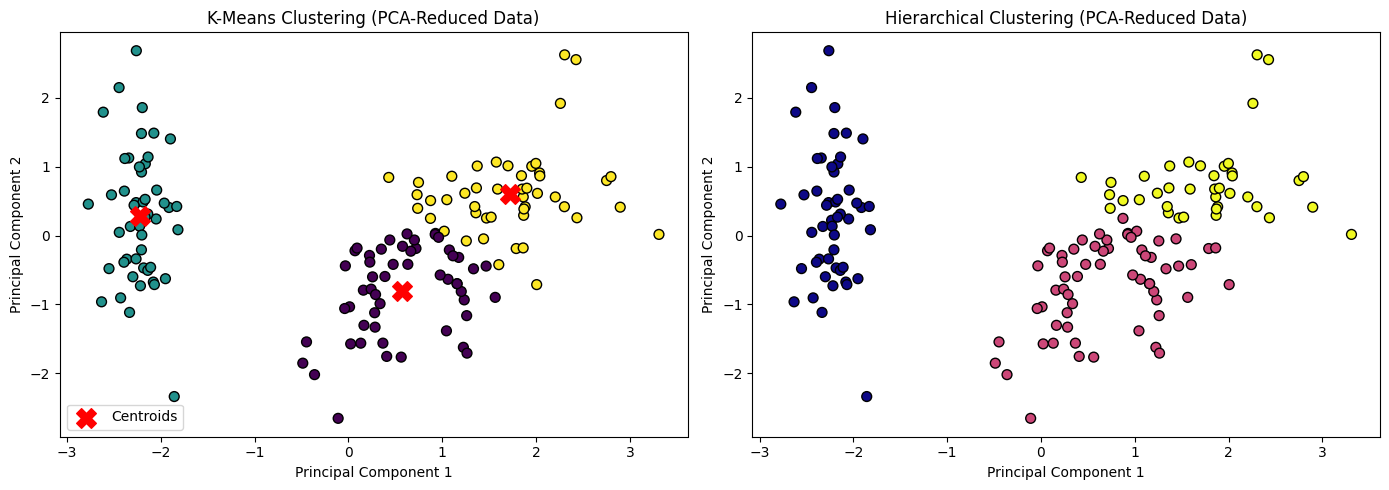

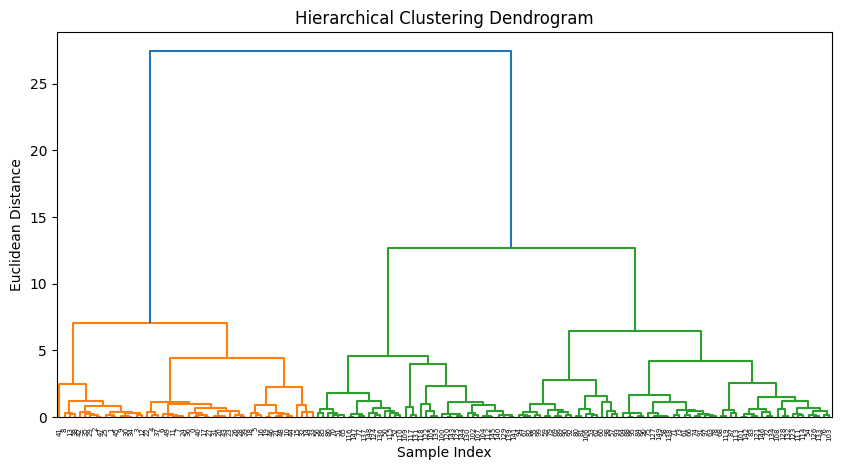

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
import scipy.cluster.hierarchy as sch

# 1. Load and Preprocess the Dataset
iris = load_iris()
X = iris.data

# Standardization is crucial for PCA and distance-based clustering algorithms
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Data Standardized successfully.\n")

# ==========================================
# 2. Principal Component Analysis (PCA)
# ==========================================
# Reduce from 4 dimensions to 2 dimensions for easier visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("--- PCA Summary ---")
print(f"Original shape: {X_scaled.shape}")
print(f"Reduced shape: {X_pca.shape}")
print(f"Explained Variance Ratio: {pca.explained_variance_ratio_}\n")

# ==========================================
# 3. K-Means Clustering
# ==========================================
# Applying K-Means on the PCA-reduced data
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

print("--- K-Means Clustering ---")
print("K-Means Cluster Centers:\n", kmeans.cluster_centers_)
print("K-Means Labels assigned successfully.\n")

# ==========================================
# 4. Hierarchical Clustering
# ==========================================
# Applying Agglomerative Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X_pca)

print("--- Hierarchical Clustering ---")
print("Hierarchical Labels assigned successfully.\n")

# ==========================================
# 5. Visualizing the Results
# ==========================================
plt.figure(figsize=(14, 5))

# Plot 1: K-Means Results
plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', edgecolor='k', s=50)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=200, c='red', marker='X', label='Centroids')
plt.title("K-Means Clustering (PCA-Reduced Data)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()

# Plot 2: Hierarchical Clustering Results
plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=hierarchical_labels, cmap='plasma', edgecolor='k', s=50)
plt.title("Hierarchical Clustering (PCA-Reduced Data)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

# Optional: Generate a Dendrogram to visualize the hierarchical building process
plt.figure(figsize=(10, 5))
plt.title("Hierarchical Clustering Dendrogram")
dendrogram = sch.dendrogram(sch.linkage(X_pca, method='ward'))
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")
plt.show()

New Point: [[5 0]]
Predicted Class: [1]


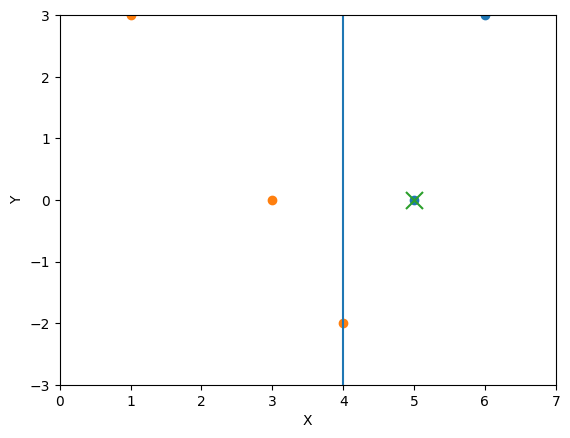

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

X = np.array([
    [5,0],
    [6,3],
    [8,-2],
    [1,3],
    [3,0],
    [4,-2]
])

y = np.array([1,1,1,-1,-1,-1])


model = SVC(kernel='linear')
model.fit(X, y)


new_point = np.array([[5,0]])

prediction = model.predict(new_point)

print("New Point:", new_point)
print("Predicted Class:", prediction)


plt.scatter(X[y==1][:,0], X[y==1][:,1])
plt.scatter(X[y==-1][:,0], X[y==-1][:,1])


w = model.coef_[0]
b = model.intercept_[0]
plt.axvline(x = -b/w[0])


plt.scatter(new_point[0][0], new_point[0][1], marker='x', s=150)

plt.xlabel("X")
plt.ylabel("Y")
plt.xlim(0,7)
plt.ylim(-3,3)
plt.show()

Explained variance ratio per principal component: [0.72962445 0.22850762]
Total explained variance: 0.9581320720000166


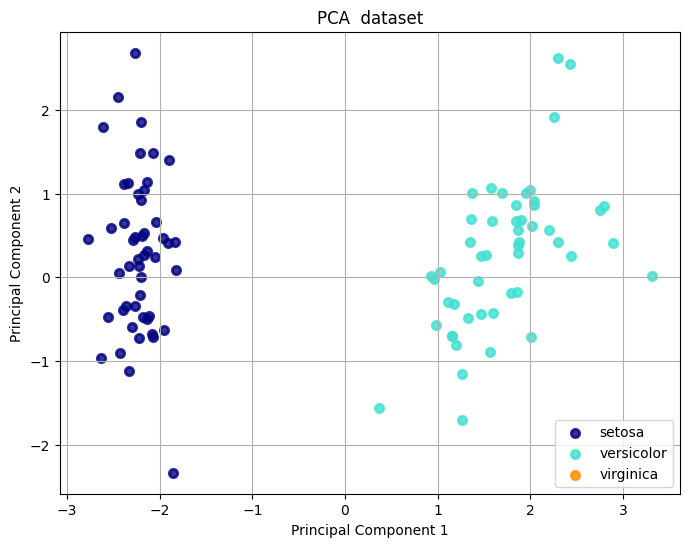

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 4. Print Explained Variance
print("Explained variance ratio per principal component:", pca.explained_variance_ratio_)
print("Total explained variance:", sum(pca.explained_variance_ratio_))

# 5. Visualize the projected PCA coordinates
plt.figure(figsize=(8, 6))
colors = ['navy', 'turquoise', 'darkorange']

for color, i, target_name in zip(colors, [0, 2, 4], target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], color=color, alpha=.8, lw=2,
                label=target_name)

plt.legend(loc='best', shadow=False, scatterpoints=1)
plt.title('PCA  dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

Support Vector Machine with Multiple Kernel Functions

In [1]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Load Dataset
data = load_breast_cancer()
X, y = data.data, data.target

# 2. Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 3. Standardize features (crucial for SVM margin calculations)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Define Kernel configurations
kernels = {
    "Linear": SVC(kernel='linear', C=1.0, random_state=42),
    "Polynomial (degree=3)": SVC(kernel='poly', degree=3, C=1.0, random_state=42),
    "RBF": SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
}

# 5. Train, Predict, and Evaluate
results = {}
for name, model in kernels.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results[name] = (acc, y_pred)
    print(f"================ {name} Kernel ================")
    print(f"Accuracy: {acc * 100:.2f}%\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=data.target_names))

================ Linear Kernel ================
Accuracy: 98.60%

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143

================ Polynomial (degree=3) Kernel ================
Accuracy: 90.21%

Classification Report:
              precision    recall  f1-score   support

   malignant       1.00      0.74      0.85        53
      benign       0.87      1.00      0.93        90

    accuracy                           0.90       143
   macro avg       0.93      0.87      0.89       143
weighted avg       0.92      0.90      0.90       143

================ RBF Kernel ================
Accuracy: 97.90%

Classification Report:
              precision    recall  f1-score   support

   malignant

Dimensionality Reduction Using Principal Component Analysis (PCA)

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load Iris Dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names

# 2. Standardize feature values to zero-mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply PCA to reduce from 4 to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 4. Construct DataFrame for transformed representation
df_pca = pd.DataFrame(data=X_pca, columns=['Principal Component 1', 'Principal Component 2'])
df_pca['Target'] = y
df_pca['Species'] = df_pca['Target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

# 5. Display statistical summary
explained_variance = pca.explained_variance_ratio_
print("Original Shape:", X.shape)
print("Transformed Shape:", X_pca.shape)
print(f"Explained Variance Ratio by Component: PC1 = {explained_variance[0]:.4f}, PC2 = {explained_variance[1]:.4f}")
print(f"Total Retained Variance: {np.sum(explained_variance) * 100:.2f}%\n")

print("First 5 Transformed Samples:")
print(df_pca.head())

Original Shape: (150, 4)
Transformed Shape: (150, 2)
Explained Variance Ratio by Component: PC1 = 0.7296, PC2 = 0.2285
Total Retained Variance: 95.81%

First 5 Transformed Samples:
   Principal Component 1  Principal Component 2  Target Species
0              -2.264703               0.480027       0  setosa
1              -2.080961              -0.674134       0  setosa
2              -2.364229              -0.341908       0  setosa
3              -2.299384              -0.597395       0  setosa
4              -2.389842               0.646835       0  setosa


Dataset Creation and Ingestion Techniques in Python

In [3]:
import io
import pandas as pd
from sklearn.datasets import load_diabetes

# ==============================================================
# Part I: Dataset Creation using Pandas
# ==============================================================
print("--- Part I: In-Memory Dataset Creation (Pandas) ---")
student_dict = {
    'Roll_No': [101, 102, 103, 104, 105],
    'Name': ['Aarav', 'Bhavna', 'Chetan', 'Divya', 'Eshwar'],
    'Machine_Learning_Score': [88, 92, 79, 95, 84],
    'Attendance_Pct': [91.0, 95.5, 82.0, 98.0, 89.5]
}

df_custom = pd.DataFrame(student_dict)
print(df_custom)
print("\nDataFrame Info:")
print(df_custom.dtypes)

# ==============================================================
# Part II: Loading CSV Dataset Files using Pandas
# ==============================================================
print("\n--- Part II: Loading CSV File into Pandas ---")
# Simulating a local CSV file in-memory using io.StringIO
csv_buffer = io.StringIO("""Emp_ID,Department,Years_Experience,Salary_LPA
E01,Data Science,3,12.5
E02,Engineering,5,16.0
E03,Product,2,10.0
E04,Data Science,6,22.0
""")

# Standard file loading: df_csv = pd.read_csv('employees.csv')
df_csv = pd.read_csv(csv_buffer)
print(df_csv.head())

# ==============================================================
# Part III: Loading Datasets using Scikit-Learn
# ==============================================================
print("\n--- Part III: Loading Toy Datasets from Sklearn ---")
# as_frame=True loads feature data and targets into Pandas DataFrames/Series directly
diabetes_bunch = load_diabetes(as_frame=True)
df_diabetes_features = diabetes_bunch.data
series_diabetes_target = diabetes_bunch.target

print("Diabetes Dataset Feature Shape:", df_diabetes_features.shape)
print("Target Variable Shape:", series_diabetes_target.shape)
print("\nFirst 3 Records with Target:")
df_combined = df_diabetes_features.copy()
df_combined['Disease_Progression'] = series_diabetes_target
print(df_combined.iloc[:3, :5])  # Displaying first 5 columns for brevity

--- Part I: In-Memory Dataset Creation (Pandas) ---
   Roll_No    Name  Machine_Learning_Score  Attendance_Pct
0      101   Aarav                      88            91.0
1      102  Bhavna                      92            95.5
2      103  Chetan                      79            82.0
3      104   Divya                      95            98.0
4      105  Eshwar                      84            89.5

DataFrame Info:
Roll_No                     int64
Name                       object
Machine_Learning_Score      int64
Attendance_Pct            float64
dtype: object

--- Part II: Loading CSV File into Pandas ---
  Emp_ID    Department  Years_Experience  Salary_LPA
0    E01  Data Science                 3        12.5
1    E02   Engineering                 5        16.0
2    E03       Product                 2        10.0
3    E04  Data Science                 6        22.0

--- Part III: Loading Toy Datasets from Sklearn ---
Diabetes Dataset Feature Shape: (442, 10)
Target Variable Shap